# Actividad | Dataset - Notebook | Individual
## Operaciones de aprenizaje automatico — TC5061.10


- Edwin Yassain Juarez Cortes — A01797884


In [1]:
import sys
!{sys.executable} -m pip install mlflow

from pathlib import Path
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from google.colab import drive
drive.mount('/content/drive')

import mlflow
import mlflow.sklearn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.

## CARGA DE LA BASE DE DATOS

Se carga base de datos de KaggleHub el conjunto wisam1985/iot-agriculture-2024. Se buscan todos los archivos CSV y se leen en tablas de pandas. Si hubiera varios CSV, se apilarían en un mismo DataFrame. source_file y symbol identifican el archivo de cada registro y son metadatos añadidos. La carga observada tiene 37,922 registros, 13 columnas originales más 2 metadatos agregados. La columna de temperatura aparece como `tempreature`; se conserva ese nombre literal para evitar excluirla.

In [2]:
# ============================================================
# 1. CARGA DE LA BASE DE DATOS
# ============================================================

sns.set_theme(style="whitegrid")  # estilo visual consistente
RANDOM_STATE = 42
DATASET_ID = "wisam1985/iot-agriculture-2024"
TARGET = "Fan_actuator_ON"
SENSOR_FEATURES = ["tempreature", "humidity", "water_level", "N", "P", "K"]  # "tempreature" conserva la escritura que trae el CSV
EXPERIMENT_NAME = "actividad_agricultura_iot_6_features"  # separa esta corrida de la versión anterior sin temperatura

ruta = Path(kagglehub.dataset_download(DATASET_ID))  # descarga y cachea el dataset
archivos_csv = sorted(ruta.rglob("*.csv"))
if not archivos_csv:
    raise FileNotFoundError(f"No se encontraron CSV dentro de {ruta}")

partes = []  # acumula cada archivo CSV antes de concatenarlos
for archivo in archivos_csv:
    parte = pd.read_csv(archivo)
    parte["source_file"] = archivo.name
    parte["symbol"] = re.sub(r"\.csv$", "", archivo.name, flags=re.IGNORECASE)
    partes.append(parte)
df = pd.concat(partes, ignore_index=True, sort=False)

# Validar columnas sensoras para evitar que una diferencia de escritura las excluya silenciosamente.
missing_sensors = [col for col in SENSOR_FEATURES if col not in df.columns]
if missing_sensors:
    raise KeyError(f"Faltan sensores requeridos: {missing_sensors}. Columnas recibidas: {df.columns.tolist()}")
print("Sensores usados en EDA/modelo:", SENSOR_FEATURES)
print(f"Archivos CSV: {len(archivos_csv)} | Registros: {len(df):,} | Variables: {df.shape[1]}")
display(df.head())

100%|██████████| 145k/145k [00:00<00:00, 625kB/s]

Extracting files...


Archivos CSV: 1 | Registros: 37,922 | Variables: 15


,date,tempreature,humidity,water_level,N,P,K,Fan_actuator_OFF,Fan_actuator_ON,Watering_plant_pump_OFF,Watering_plant_pump_ON,Water_pump_actuator_OFF,Water_pump_actuator_ON,source_file,symbol
0,2024-02-08 06:10:00,41,63,100,255,255,255,0.0,1.0,1.0,0.0,1.0,0.0,IoTProcessed_Data.csv,IoTProcessed_Data
1,2024-02-08 06:15:00,41,59,100,255,255,255,0.0,1.0,1.0,0.0,1.0,0.0,IoTProcessed_Data.csv,IoTProcessed_Data
2,2024-02-08 06:20:00,41,62,100,255,255,255,0.0,1.0,1.0,0.0,1.0,0.0,IoTProcessed_Data.csv,IoTProcessed_Data
3,2024-02-08 06:05:00,40,60,100,255,255,255,0.0,1.0,1.0,0.0,1.0,0.0,IoTProcessed_Data.csv,IoTProcessed_Data
4,2024-02-08 06:00:00,39,61,100,255,255,255,0.0,1.0,1.0,0.0,1.0,0.0,IoTProcessed_Data.csv,IoTProcessed_Data


In [3]:
# ============================================================
# 1.1 DESCRIPCION DE LA BASE DE DATOS
# ============================================================
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "faltantes": df.isna().sum(),
    "faltantes_%": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True),
})
display(estructura)
print("Registros duplicados exactos:", df.duplicated().sum())

,tipo,no_nulos,faltantes,faltantes_%,valores_unicos
date,object,37920,2,0.01,28682
tempreature,int64,37922,0,0.00,39
humidity,int64,37922,0,0.00,101
water_level,int64,37922,0,0.00,101
N,int64,37922,0,0.00,8
P,int64,37922,0,0.00,9
K,int64,37922,0,0.00,9
Fan_actuator_OFF,float64,37922,0,0.00,2
Fan_actuator_ON,float64,37922,0,0.00,2
Watering_plant_pump_OFF,float64,37922,0,0.00,2


Registros duplicados exactos: 0


In [ ]:
descripciones = {
    "date": "Fecha/hora de captura del sensor.",
    "tempreature": "Temperatura dentro del invernadero (nombre escrito así en el CSV).",
    "humidity": "Humedad ambiental.",
    "water_level": "Nivel de agua/humedad del suelo.",
    "N": "Nivel de nitrógeno en suelo (escala reportada 0-255).",
    "P": "Nivel de fósforo en suelo (escala reportada 0-255).",
    "K": "Nivel de potasio en suelo (escala reportada 0-255).",
    "Fan_actuator_ON": "Indicador de que el ventilador está encendido; objetivo elegido.",
    "Fan_actuator_OFF": "Indicador de que el ventilador está apagado; excluido para evitar fuga del objetivo.",
    "Watering_plant_pump_ON": "Estado ON de la bomba de riego de planta; excluido del modelo.",
    "Watering_plant_pump_OFF": "Estado OFF de la bomba de riego de planta; excluido del modelo.",
    "Water_pump_actuator_ON": "Estado ON de la bomba de agua; excluido del modelo.",
    "Water_pump_actuator_OFF": "Estado OFF de la bomba de agua; excluido del modelo.",
    "source_file": "Archivo CSV del que proviene el registro (metadato agregado).",
    "symbol": "Nombre del archivo sin extensión (metadato agregado).",
}
variables = pd.DataFrame({"variable": df.columns})
variables["tipo_observado"] = variables.variable.map(estructura["tipo"])
variables["significado"] = variables.variable.map(descripciones).fillna("No documentado en la ficha consultada; inspeccionar diccionario del dataset.")
display(variables)

##Análisis exploratorio: resúmenes estadísticos
describe(include="all") resume variables numéricas y categóricas. Para las numéricas se agregan asimetría y curtosis de Fisher. La asimetría describe hacia qué lado se extiende más la distribución; la curtosis compara el peso de las colas con una normal. Para las categóricas, describe informa cantidad de valores, categorías y la más frecuente. Estas medidas describen la muestra, no demuestran causalidad ni que los sensores sigan una distribución normal.

In [5]:
# ============================================================
# 2. ANALISIS EXPLORATORIO
# ============================================================

# Estadísticas descriptivas completas (numéricas y categóricas)
display(df.describe(include="all").T)

# Estadísticas numéricas con asimetría y curtosis de Fisher (0 ~ normal en curtosis)
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    resumen_num = df[numeric_cols].describe().T
    resumen_num["asimetria"] = df[numeric_cols].skew()
    resumen_num["curtosis_fisher"] = df[numeric_cols].kurtosis()
    display(resumen_num)

# Resumen categórico explícito (incluye frecuencia de la categoría más común)
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
if categorical_cols:
    resumen_cat = df[categorical_cols].describe().T
    display(resumen_cat)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,37920,28682,2024-01-12 04:04:00,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tempreature,37922.0,NaN,NaN,NaN,18.760113,7.143422,3.0,13.0,17.0,25.0,41.0
humidity,37922.0,NaN,NaN,NaN,50.329308,22.995645,0.0,49.0,59.0,62.0,100.0
water_level,37922.0,NaN,NaN,NaN,79.401587,36.82461,0.0,79.0,100.0,100.0,100.0
N,37922.0,NaN,NaN,NaN,231.96361,34.718121,0.0,185.0,255.0,255.0,255.0
P,37922.0,NaN,NaN,NaN,234.123332,31.452138,0.0,190.0,255.0,255.0,255.0
K,37922.0,NaN,NaN,NaN,225.171879,44.877635,0.0,160.0,255.0,255.0,259.0
Fan_actuator_OFF,37922.0,NaN,NaN,NaN,0.689863,0.462555,0.0,0.0,1.0,1.0,1.0
Fan_actuator_ON,37922.0,NaN,NaN,NaN,0.310137,0.462555,0.0,0.0,0.0,1.0,1.0
Watering_plant_pump_OFF,37922.0,NaN,NaN,NaN,0.762091,0.425809,0.0,1.0,1.0,1.0,1.0


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis_fisher
tempreature,37922.0,18.760113,7.143422,3.0,13.0,17.0,25.0,41.0,0.455618,-0.935960
humidity,37922.0,50.329308,22.995645,0.0,49.0,59.0,62.0,100.0,-1.154149,0.280461
water_level,37922.0,79.401587,36.824610,0.0,79.0,100.0,100.0,100.0,-1.490428,0.449579
N,37922.0,231.963610,34.718121,0.0,185.0,255.0,255.0,255.0,-0.863945,-1.129704
P,37922.0,234.123332,31.452138,0.0,190.0,255.0,255.0,255.0,-0.867346,-1.060967
K,37922.0,225.171879,44.877635,0.0,160.0,255.0,255.0,259.0,-0.844090,-1.265481
Fan_actuator_OFF,37922.0,0.689863,0.462555,0.0,0.0,1.0,1.0,1.0,-0.820976,-1.326069
Fan_actuator_ON,37922.0,0.310137,0.462555,0.0,0.0,0.0,1.0,1.0,0.820976,-1.326069
Watering_plant_pump_OFF,37922.0,0.762091,0.425809,0.0,1.0,1.0,1.0,1.0,-1.231089,-0.484445
Watering_plant_pump_ON,37922.0,0.237909,0.425809,0.0,0.0,0.0,0.0,1.0,1.231089,-0.484445


,count,unique,top,freq
date,37920,28682,2024-01-12 04:04:00,10
source_file,37922,1,IoTProcessed_Data.csv,37922
symbol,37922,1,IoTProcessed_Data,37922


##Distribuciones y valores extremos
Para cada sensor se dibuja un histograma, una curva KDE suavizada y una curva normal de referencia calculada con la media y desviación estándar observadas. Así se puede ver si los datos se concentran en uno o varios rangos, muestran sesgo o difieren de una forma normal. Los boxplots resumen mediana y cuartiles y señalan posibles extremos; esos puntos requieren revisión antes de decidir si son errores.

In [ ]:
# Distribución de cada sensor: histograma, KDE y curva normal como referencia
missing_sensors = [c for c in SENSOR_FEATURES if c not in df.columns]
if missing_sensors:
    raise KeyError(f"No se pueden graficar todos los sensores: faltan {missing_sensors}")
sensor_cols = SENSOR_FEATURES.copy()  # incluye explícitamente los seis sensores
sensor_num = pd.DataFrame({c: pd.to_numeric(df[c], errors="coerce") for c in sensor_cols}).dropna(axis=1, how="all")
if sensor_num.shape[1]:
    ncols = 2
    nrows = int(np.ceil(sensor_num.shape[1] / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, sensor_num.columns):
        serie = sensor_num[col].dropna()
        sns.histplot(serie, stat="density", kde=True, bins=30, ax=ax, color="steelblue", label="Histograma + KDE")
        media, desviacion = serie.mean(), serie.std()
        if desviacion > 0:
            x = np.linspace(serie.min(), serie.max(), 200)
            y_normal = np.exp(-0.5*((x-media)/desviacion)**2)/(desviacion*np.sqrt(2*np.pi))
            ax.plot(x, y_normal, color="darkred", linestyle="--", label="Normal de referencia")
        ax.set_title(f"Distribución de {col}"); ax.set_xlabel(col); ax.set_ylabel("Densidad"); ax.legend()
    for ax in axes[len(sensor_num.columns):]: ax.remove()
    plt.tight_layout(); plt.show()

# Boxplots por sensor para apreciar rango, dispersión y posibles valores extremos
if sensor_num.shape[1]:
    fig, axes = plt.subplots(sensor_num.shape[1], 1, figsize=(11, 2.6*sensor_num.shape[1]))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, sensor_num.columns):
        sns.boxplot(x=sensor_num[col], ax=ax, color="lightblue")
        ax.set_title(f"Boxplot de {col}"); ax.set_xlabel(col)
    plt.tight_layout(); plt.show()


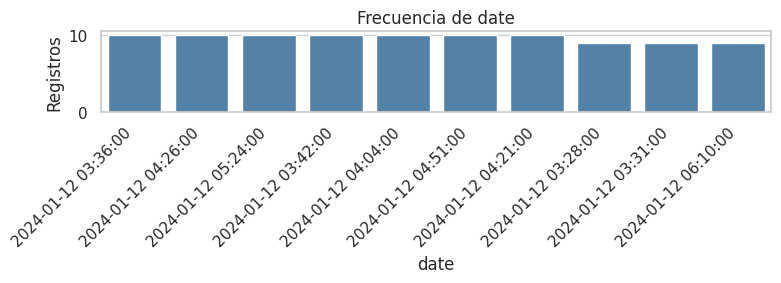

,frecuencia
date,
2024-01-12 03:36:00,10
2024-01-12 04:26:00,10
2024-01-12 05:24:00,10
2024-01-12 03:42:00,10
2024-01-12 04:04:00,10
2024-01-12 04:51:00,10
2024-01-12 04:21:00,10
2024-01-12 03:28:00,9
2024-01-12 03:31:00,9


In [7]:
# Frecuencias de variables categóricas. Para cardinalidad alta se muestran las 10 categorías más frecuentes.
cat_cols_eda = [c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
                if c not in {"source_file", "symbol"}]
for col in cat_cols_eda:
    frecuencias_cat = df[col].value_counts(dropna=False).head(10)
    plt.figure(figsize=(8,3))
    sns.barplot(x=frecuencias_cat.index.astype(str), y=frecuencias_cat.values, color="steelblue")
    plt.title(f"Frecuencia de {col}"); plt.xlabel(col); plt.ylabel("Registros")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
    display(frecuencias_cat.rename("frecuencia").to_frame())


##Sensores y estado del ventilador
Los boxplots comparan los valores de cada sensor entre las clases del objetivo. Las barras apiladas muestran la proporción de Fan_actuator_ON según categorías de otras columnas. Sirven para detectar diferencias que podrían ser útiles para predecir. Los estados de otros actuadores se exploran, pero no se introducen como predictores para evitar fuga de información.

In [ ]:
# Relaciones entre sensores: dispersión (muestra de hasta 1,500 registros) y correlación de Pearson
if sensor_num.shape[1] >= 2:
    muestra = sensor_num.sample(n=min(1500, len(sensor_num)), random_state=RANDOM_STATE)
    sns.pairplot(muestra, diag_kind="hist", corner=True, plot_kws={"alpha":0.35, "s":18})
    plt.suptitle("Relaciones entre variables sensoras (muestra)", y=1.02); plt.show()
    corr = sensor_num.corr(method="pearson")
    plt.figure(figsize=(8,6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
    plt.title("Correlación de Pearson entre sensores"); plt.tight_layout(); plt.show()
    display(corr)
else:
    print("Se necesitan al menos dos sensores numéricos para analizar relaciones.")


In [ ]:
# Relación de sensores con el estado del ventilador (objetivo)
if TARGET in df.columns and sensor_num.shape[1]:
    eda_obj = sensor_num.copy()
    eda_obj[TARGET] = df[TARGET].astype(str).values
    print(f"Distribución del objetivo {TARGET}:")
    display(eda_obj[TARGET].value_counts(dropna=False).rename("frecuencia").to_frame())
    for col in sensor_num.columns:
        plt.figure(figsize=(7,4))
        sns.boxplot(data=eda_obj, x=TARGET, y=col)
        plt.title(f"{col} según {TARGET}"); plt.xlabel("Estado del ventilador"); plt.ylabel(col)
        plt.tight_layout(); plt.show()

    # Proporciones del estado objetivo por cada categoría de los demás indicadores categóricos
    otras_categoricas = [c for c in cat_cols_eda if c != TARGET and df[c].nunique(dropna=True) <= 20]
    for col in otras_categoricas:
        tabla = pd.crosstab(df[col].fillna("(faltante)").astype(str), df[TARGET].astype(str), normalize="index")
        tabla.plot(kind="bar", stacked=True, figsize=(8,3), colormap="Set2")
        plt.title(f"Proporción de {TARGET} según {col}"); plt.xlabel(col); plt.ylabel("Proporción")
        plt.xticks(rotation=45, ha="right"); plt.legend(title=TARGET, bbox_to_anchor=(1.02,1), loc="upper left")
        plt.tight_layout(); plt.show()
else:
    print(f"No se puede analizar el objetivo: no se encontró {TARGET!r} o faltan sensores numéricos.")


## Limpieza y decisiones específicas observadas
- **Duplicados:** se contaron 0 filas duplicadas exactas; no se eliminan registros por este motivo.
- **Faltantes:** la etiqueta y los seis sensores no presentan valores faltantes. La columna `date` tiene 2 faltantes de 37,922 (0.01%); se convierte a fecha/hora y se conservan esas filas porque `date` no se usa como predictor.
- **Tipos:** los seis sensores están almacenados como enteros. Los indicadores de actuadores y el objetivo son valores 0/1 originalmente `float64`; el código los convierte a entero anulable para reflejar su naturaleza binaria.
- **Rangos:** humedad y nivel de agua están entre 0 y 100. N, P y K se documentan con máximo 255; se encontró un valor `K=259`. Se conserva y se reporta para verificarlo con la fuente, sin recortarlo ni borrarlo automáticamente.
- **Extremos:** el criterio IQR se calcula solo para sensores, no para indicadores binarios. Marca 7,589 observaciones de humedad (20.0%) y 7,044 de `water_level` (18.6%); como ambos campos permanecen dentro de 0–100, se consideran lecturas plausibles y se conservan. El IQR no decide por sí mismo que una observación sea errónea.
- **Etiqueta:** se eliminan filas solo si falta `Fan_actuator_ON`; en los datos observados fueron 0.

El objetivo de estas reglas es corregir tipos, detectar anomalías verificables y mantener lecturas plausibles. La imputación de sensores, si llegara a ser necesaria, se hace dentro del pipeline y solo con entrenamiento.


## Hallazgos escritos del EDA
- **Tamaño y cobertura:** 37,922 registros. `date` tiene 37,920 valores válidos y dos faltantes; los sensores y el objetivo tienen cobertura completa.
- **Temperatura (`tempreature`):** media 18.76, mediana 17, mínimo 3 y máximo 41; asimetría positiva leve (0.46). Al agrupar por `Fan_actuator_ON`, la mediana es 14 para clase 0 y 28 para clase 1, una diferencia clara en esta muestra.
- **Humedad y agua:** humedad tiene media 50.33 y mediana 59 (asimetría -1.15); `water_level` tiene media 79.40 y mediana 100 (asimetría -1.49). Ambas variables se concentran en valores altos y tienen una cola hacia valores bajos.
- **Nutrientes:** N, P y K se concentran cerca del límite 255, con medianas de 255 y correlaciones casi perfectas entre sí (N-P 0.9997, N-K 0.9990, P-K 0.9993). Esto sugiere información muy redundante y posible saturación/codificación en el dataset; no implica que sean tres señales independientes.
- **Objetivo:** 11,761 casos con ventilador encendido (31.0%) y 26,161 apagado (69.0%). Hay un desbalance moderado, por lo que se revisan F1 macro y métricas por clase además de accuracy.
- **Relaciones entre sensores:** temperatura muestra correlación negativa moderada-baja con nivel de agua (-0.251) y débil con humedad (-0.139); N, P y K se mueven prácticamente juntos. La relación temperatura-objetivo es especialmente marcada y debe validarse fuera de una partición aleatoria antes de extrapolar.

Estos hallazgos describen la descarga actual; vuelve a ejecutar las celdas EDA para actualizar los gráficos con los seis sensores, incluida `tempreature`.


In [ ]:
# ============================================================
# 3. LIMPIEZA Y VALIDACIÓN
# ============================================================
# Normaliza encabezados y convierte celdas vacías o con solo espacios en nulos.
df.columns = [str(c).strip() for c in df.columns]
df = df.replace(r"^\s*$", np.nan, regex=True)

# Elimina duplicados exactos; en la carga observada no se encontró ninguno.
antes = len(df)
df = df.drop_duplicates().copy()
print(f"Duplicados exactos eliminados: {antes-len(df)}")

# La columna temporal de la fuente se llama "date" (minúsculas), no "Date".
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    print("Fechas faltantes o no convertibles:", int(df["date"].isna().sum()), "(se conservan; date no es predictor)")

# Convierte columnas a numéricas solo si al menos 95% de valores son convertibles.
for c in df.columns:
    if c in {"source_file", "symbol", TARGET, "date"}:
        continue
    if pd.api.types.is_numeric_dtype(df[c]):
        continue
    convertido = pd.to_numeric(df[c].astype(str).str.replace(",", "", regex=False), errors="coerce")
    if convertido.notna().mean() >= 0.95:
        df[c] = convertido
        print(f"Conversión a numérico: {c}")

# Los indicadores de actuadores y el objetivo contienen 0/1; se tipan como enteros anulables.
binary_cols = [TARGET, "Fan_actuator_OFF", "Watering_plant_pump_ON", "Watering_plant_pump_OFF", "Water_pump_actuator_ON", "Water_pump_actuator_OFF"]
for c in binary_cols:
    if c in df.columns and set(df[c].dropna().unique()).issubset({0, 1, 0.0, 1.0}):
        df[c] = df[c].astype("Int8")

# Verifica rangos documentados. El dato se conserva y se reporta para no corregirlo sin evidencia.
rangos_esperados = {"humidity": (0, 100), "water_level": (0, 100), "N": (0, 255), "P": (0, 255), "K": (0, 255)}
for c, (minimo, maximo) in rangos_esperados.items():
    if c in df.columns:
        fuera = ((df[c] < minimo) | (df[c] > maximo)).sum()
        print(f"{c}: {fuera} valores fuera del rango documentado [{minimo}, {maximo}]")

# Sin etiqueta no puede haber aprendizaje supervisado; no se eliminaron filas en la carga observada.
if TARGET not in df.columns:
    raise KeyError(f"No se encontró TARGET={TARGET!r}. Columnas disponibles: {df.columns.tolist()}")
antes = len(df)
df = df.dropna(subset=[TARGET]).copy()
print(f"Filas sin objetivo eliminadas: {antes-len(df)}")

# Reporta posibles extremos solo en sensores; IQR no es apropiado para indicadores binarios 0/1.
sensor_num_limpio = df[SENSOR_FEATURES].apply(pd.to_numeric, errors="coerce")
resumen_iqr = []
for c in sensor_num_limpio.columns:
    serie = sensor_num_limpio[c].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3-q1
    inferior, superior = q1-1.5*iqr, q3+1.5*iqr
    n_out = ((serie < inferior) | (serie > superior)).sum()
    resumen_iqr.append({"variable": c, "limite_inferior_IQR": inferior, "limite_superior_IQR": superior,
                        "outliers": int(n_out), "outliers_%": 100*n_out/len(serie)})
outliers = pd.DataFrame(resumen_iqr).sort_values("outliers_%", ascending=False)
display(outliers)
print("Filas/variables tras limpieza estructural:", df.shape)


## Entrenamiento del modelo base
El objetivo es predecir `Fan_actuator_ON`. Se usan seis predictores: `tempreature`, `humidity`, `water_level`, `N`, `P` y `K`. La temperatura se escribe `tempreature` porque ese es el encabezado real del CSV. El código verifica que estén las seis variables y genera un error descriptivo si falta alguna; ya no filtra columnas silenciosamente.

Se excluyen `date`, identificadores y estados de otros actuadores para reducir fuga de información. Se conserva la división estratificada 80/20 y el Random Forest de 200 árboles con ponderación balanceada. Al ejecutar, la celda debe imprimir `Predictores: 6` y listar las seis variables. El experimento MLflow nuevo se llama `actividad_agricultura_iot_6_features` para distinguirlo de la corrida previa.


In [ ]:
# ============================================================
# 4. ENTRENAMIENTO DEL MODELO BASE
# ============================================================
# Solo predictores disponibles en el dataset y conocidos antes de accionar el ventilador.
missing_features = [c for c in SENSOR_FEATURES if c not in df.columns]
if missing_features:
    raise KeyError(f"No se entrenará con un subconjunto: faltan {missing_features}. Columnas: {df.columns.tolist()}")
features = SENSOR_FEATURES.copy()
X = df[features].copy()
y = df[TARGET].astype(str)
# Eliminar columnas totalmente vacías para que el pipeline sea válido.
X = X.dropna(axis=1, how="all")
if X.shape[1] == 0:
    raise ValueError("No quedan predictores después de excluir identificadores.")

frecuencias = y.value_counts()
stratify = y if (len(frecuencias) > 1 and frecuencias.min() >= 2) else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=stratify
)

preprocesador = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), make_column_selector(dtype_include=np.number)),
    ("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), make_column_selector(dtype_exclude=np.number)),
], remainder="drop")
modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1)),
])
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)
print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,} | Predictores: {X.shape[1]}")
print("Predictores usados:", features)

Entrenamiento: 30,337 | Prueba: 7,585 | Predictores: 6
Predictores usados: ['tempreature', 'humidity', 'water_level', 'N', 'P', 'K']


## Evaluación del modelo corregido
Con la división aleatoria estratificada 80/20 y los seis sensores, la ejecución reproducible de esta configuración obtuvo **accuracy = 1.0000** y **F1 macro = 1.0000** sobre 7,585 filas de prueba. La clase 0 tuvo soporte 5,233 y la clase 1 soporte 2,352. La matriz de confusión se actualizará al volver a ejecutar la celda.

Este resultado perfecto requiere cautela. `tempreature` presenta una fuerte separación observada entre las etiquetas (mediana de 14 para estado 0 y 28 para estado 1) y tiene importancia de 0.92 en el Random Forest. Esto sugiere que la etiqueta puede depender casi directamente de una regla sobre temperatura en este dataset. La división aleatoria puede además mezclar registros temporales cercanos entre entrenamiento y prueba. Antes de concluir que el modelo generaliza, conviene evaluar una partición cronológica y validar con datos nuevos del invernadero.


Accuracy: 1.0000
F1 macro: 1.0000

Reporte por clase:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      5233
         1.0       1.00      1.00      1.00      2352

    accuracy                           1.00      7585
   macro avg       1.00      1.00      1.00      7585
weighted avg       1.00      1.00      1.00      7585



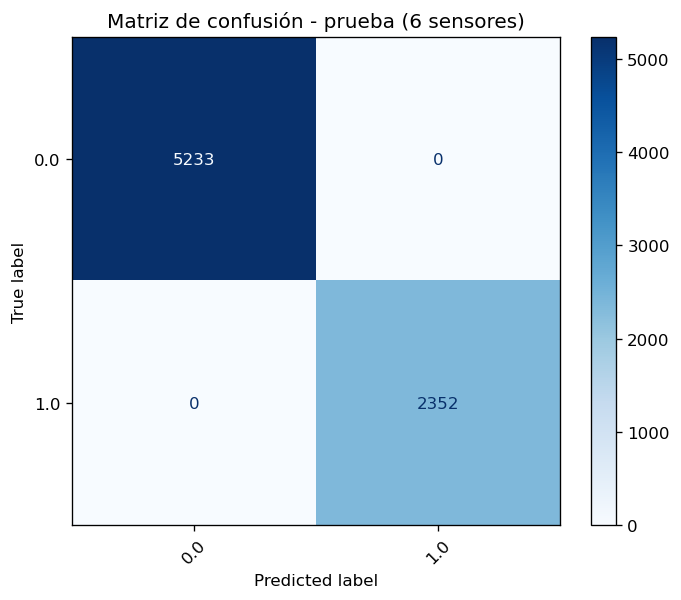

In [ ]:
# ============================================================
# 5. EVALUACION DEL MODELO
# ============================================================
accuracy = accuracy_score(y_test, pred)
f1_macro = f1_score(y_test, pred, average="macro", zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"F1 macro: {f1_macro:.4f}")
print("\nReporte por clase:\n", classification_report(y_test, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45, cmap="Blues")
plt.title("Matriz de confusión - prueba"); plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# 5. REGISTRO DE MLFlow
# ============================================================

mlflow.set_experiment(EXPERIMENT_NAME)
with mlflow.start_run(run_name="random_forest_baseline") as run:
    mlflow.log_params({
        "dataset_id": DATASET_ID,
        "target": TARGET,
        "model": "RandomForestClassifier",
        "n_estimators": 200,
        "class_weight": "balanced",
        "test_size": 0.20,
        "random_state": RANDOM_STATE,
        "n_rows_after_cleaning": len(df),
        "n_features_before_encoding": X.shape[1],
        "feature_columns": ",".join(features),
        "n_classes": y.nunique(),
    })
    mlflow.log_metrics({"accuracy": accuracy, "f1_macro": f1_macro})
    mlflow.sklearn.log_model(modelo, name="modelo_base_6_features", skops_trusted_types=['numpy.dtype', 'numpy.number', 'sklearn.compose._column_transformer.make_column_selector', 'sklearn.tree._tree.Tree'])
    print("Run ID:", run.info.run_id)
    print("Tracking URI:", mlflow.get_tracking_uri())


In [ ]:
# Abrir MLflow Tracking en Google Colab
# Este notebook registró los datos en SQLite, así que la UI debe apuntar al mismo URI.
import socket
import subprocess
import sys
import time
from pathlib import Path
import mlflow

tracking_uri = mlflow.get_tracking_uri()
print("Tracking URI que se va a consultar:", tracking_uri)

# Seleccionar un puerto libre
with socket.socket() as s:
    s.bind(("0.0.0.0", 0))
    puerto = s.getsockname()[1]

# Guardar los mensajes del servidor para mostrar el motivo real si falla
mlflow_server_log = "/tmp/mlflow_server.log"
log_file = open(mlflow_server_log, "w", encoding="utf-8")
comando = [
    sys.executable, "-m", "mlflow", "server",
    "--backend-store-uri", tracking_uri,
    "--default-artifact-root", str(Path("./mlartifacts").resolve()),
    "--host", "0.0.0.0",
    "--port", str(puerto),
    # Colab abre el panel desde un dominio proxy dinámico.
    "--allowed-hosts", "*",
    "--cors-allowed-origins", "*",
]
mlflow_server_process = subprocess.Popen(
    comando, stdout=log_file, stderr=subprocess.STDOUT, text=True
)

# Esperamos 3 segundos para que el servidor inicie
time.sleep(3.0)

# Verificamos si el proceso sigue activo en lugar de depender de peticiones HTTP locales que pueden fallar por red interna
if mlflow_server_process.poll() is not None:
    log_file.flush()
    detalle = Path(mlflow_server_log).read_text(encoding="utf-8", errors="replace")
    raise RuntimeError(f"MLflow terminó al iniciar. Revisa el log:\n{detalle[-5000:]}")

# Mostrar un enlace que atraviesa el proxy de Google Colab
from google.colab.output import eval_js
url_mlflow = eval_js(f"google.colab.kernel.proxyPort({puerto})")
print("\nMLflow se ha iniciado exitosamente en segundo plano.")
print("Abre MLflow Tracking aquí:", url_mlflow)
print("Al terminar, puedes detener el servidor con: mlflow_server_process.terminate()")

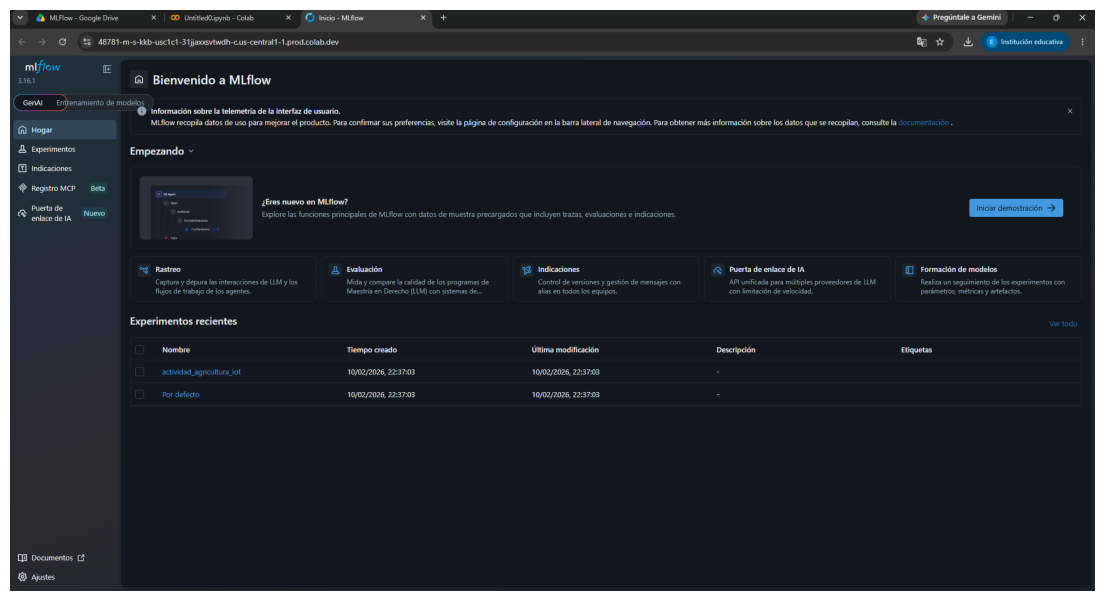

In [22]:
from PIL import Image

ruta_imagen = ('/content/drive/MyDrive/Colab Notebooks/MNA/vision_computacional/prueba.png')

# Abre y muestra la imagen
imagen = Image.open(ruta_imagen)
plt.figure(figsize=(14, 10))
plt.imshow(imagen)
plt.axis("off")
plt.show()

## Reflexión final

Esta actividad me ayudó a reconocer que la calidad del análisis depende primero de cómo se capturan y nombran los datos. La retroalimentación sobre `tempreature` mostró que un error de escritura en el encabezado puede dejar fuera una variable importante sin que el programa falle; por eso, en un proceso real incluiría validaciones del esquema y alertas cuando falten columnas esperadas. También documentaría unidades, rangos y reglas de captura para cada sensor, y registraría la versión de los datos y de las bibliotecas para reproducir los resultados. En MLOps, agregaría una evaluación cronológica y pruebas con datos de nuevas fechas, porque registros consecutivos del mismo invernadero pueden ser muy parecidos. El accuracy perfecto obtenido al incluir temperatura es prometedor para esta muestra, pero no basta para asegurar que el comportamiento se mantenga en otra temporada.

Mi área de trabajo está relacionada con la producción de semilla de maíz y la realización de actividades agrícolas con maquinaria. Estos aprendizajes me ayudan a identificar qué información conviene registrar en cada labor: fecha y lote, maquinaria y configuración, variedad, humedad del suelo, temperatura, fertilización, riego, incidencias, mano de obra, costos y rendimiento final. Si la captura es consistente, puedo comparar parcelas y temporadas, detectar operaciones que se relacionan con mejores resultados y proponer mejoras al proceso. Después mediría si esas mejoras realmente reducen costos o elevan el rendimiento. Así, el análisis de datos complementaría la experiencia de campo y ayudaría a tomar decisiones agrícolas con evidencia.
